# Statistical Analysis and Bayesian Classification

**Dataset: California Housing Dataset**

# Setup

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from scipy.stats import norm
from sklearn.metrics import accuracy_score, confusion_matrix

plt.style.use('dark_background')
np.random.seed(42)

california = fetch_california_housing()
X = np.column_stack([california.data, california.target])


In [143]:
feature_names = list(california.feature_names) + ['MedHouseVal']
feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude',
 'MedHouseVal']

In [144]:
# ndim : number of dimensions
print(f"X: ndim = {X.ndim}, shape = {X.shape}  (samples, features)\n")
for i, name in enumerate(feature_names):
    print(f"  {i}: {name:<12} min = {X[:, i].min():>9.2f}   max = {X[:, i].max():>10.2f}")

X: ndim = 2, shape = (20640, 9)  (samples, features)

  0: MedInc       min =      0.50   max =      15.00
  1: HouseAge     min =      1.00   max =      52.00
  2: AveRooms     min =      0.85   max =     141.91
  3: AveBedrms    min =      0.33   max =      34.07
  4: Population   min =      3.00   max =   35682.00
  5: AveOccup     min =      0.69   max =    1243.33
  6: Latitude     min =     32.54   max =      41.95
  7: Longitude    min =   -124.35   max =    -114.31
  8: MedHouseVal  min =      0.15   max =       5.00


In [145]:
df = pd.DataFrame(X, columns=feature_names)
print('Dataset shape:', X.shape)
print(df.head().to_string(index=False))

Dataset shape: (20640, 9)
 MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
 8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
 8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
 7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
 5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
 3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422


# Part 1: Frequency Distribution and Histograms

Using the AveBedrms feature:

1. Create a Frequency Table using bins of width 1.
2. Calculate the Count and Percentage for each bin.
3. Plot two histograms:
   - Count Histogram.
   - Density Histogram.
4. Calculate and print the total number of observations and the approximate total density area.

In [146]:
bedrms = df['AveBedrms'].to_numpy()
bin_edges = np.arange(0, 36, 1)
counts, edges = np.histogram(bedrms, bins=bin_edges)
frequency_table = pd.DataFrame({
    'Bin range': [f'[{edges[i]:.0f}, {edges[i+1]:.0f})'
                  if i < len(counts)-1
                  else f'[{edges[i]:.0f}, {edges[i+1]:.0f}]'
                  for i in range(len(counts))],
    'Count': counts,
    'Percentage (%)': np.round(counts / len(bedrms) * 100, 2)
})
print(frequency_table.to_string(index=False))
print(f'Total count: {counts.sum()}')
print(f'Total percentage: {round(100 * counts.sum()/len(bedrms), 2)}%')

Bin range  Count  Percentage (%)
   [0, 1)   4395           21.29
   [1, 2)  16004           77.54
   [2, 3)    134            0.65
   [3, 4)     40            0.19
   [4, 5)     22            0.11
   [5, 6)     16            0.08
   [6, 7)      9            0.04
   [7, 8)      4            0.02
   [8, 9)      5            0.02
  [9, 10)      2            0.01
 [10, 11)      2            0.01
 [11, 12)      3            0.01
 [12, 13)      0            0.00
 [13, 14)      0            0.00
 [14, 15)      1            0.00
 [15, 16)      1            0.00
 [16, 17)      0            0.00
 [17, 18)      0            0.00
 [18, 19)      0            0.00
 [19, 20)      0            0.00
 [20, 21)      0            0.00
 [21, 22)      0            0.00
 [22, 23)      0            0.00
 [23, 24)      0            0.00
 [24, 25)      0            0.00
 [25, 26)      1            0.00
 [26, 27)      0            0.00
 [27, 28)      0            0.00
 [28, 29)      0            0.00
 [29, 30) 

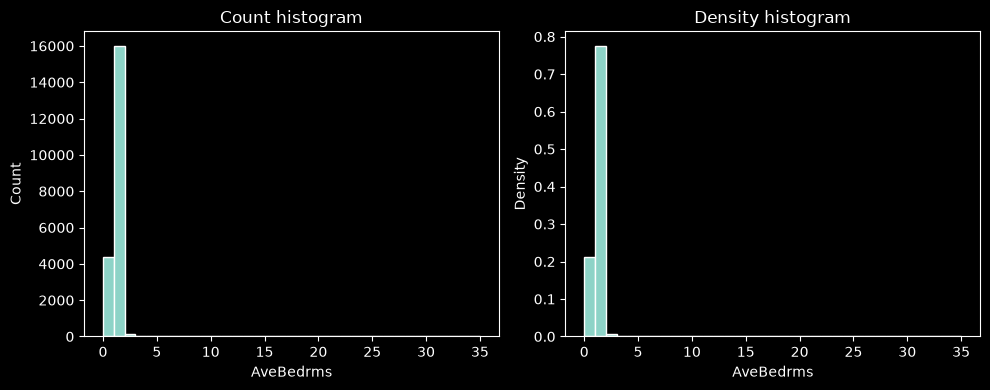

Total Observations: 20640
Approximate total density area: 1.0


In [147]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(bedrms, bins=bin_edges, edgecolor='white')
axes[0].set(title='Count histogram', xlabel='AveBedrms', ylabel='Count')
heights, bins, _ = axes[1].hist(bedrms, bins=bin_edges, density=True, edgecolor='white')
axes[1].set(title='Density histogram', xlabel='AveBedrms', ylabel='Density')
plt.tight_layout()
plt.show()
print(f'Total Observations: {len(bedrms)}')
print(f'Approximate total density area: {np.sum(heights * np.diff(bins))}')

# Part 2: Outlier Detection

Using the Population feature:

1. Calculate Q1, Median, and Q3.
2. Calculate the IQR.
3. Determine the Lower Fence and Upper Fence using the IQR rule.
4. Identify the potential outliers.
5. Plot a horizontal Box Plot showing the distribution.

In [148]:
population = df['Population'].to_numpy()
q1, median, q3 = np.percentile(population, [25, 50, 75])
print(f"Population: Q1 = {q1:.2f}, Median = {median:.2f}, Q3 = {q3:.2f}")

Population: Q1 = 787.00, Median = 1166.00, Q3 = 1725.00


In [149]:
iqr = q3 - q1
print(f"Population: IQR = {iqr:.2f}")

Population: IQR = 938.00


In [150]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(f"Population: Lower fence = {lower:.2f}, Upper fence = {upper:.2f}")

Population: Lower fence = -620.00, Upper fence = 3132.00


In [151]:
outliers = (population < lower) | (population > upper)
print(f"Population: Potential outliers = {outliers.sum()}")

Population: Potential outliers = 1196


C:\Users\IFLEX\AppData\Local\Temp\ipykernel_23084\4235656987.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes.boxplot(population, vert=False)


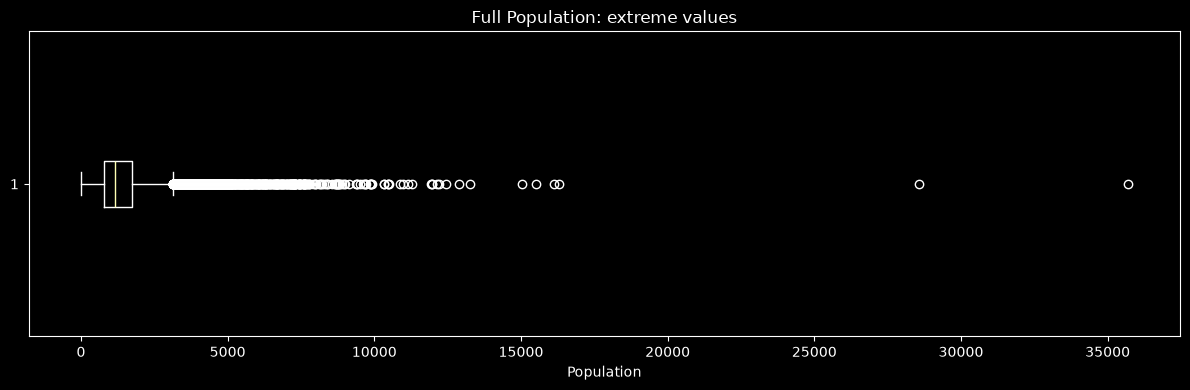

In [152]:
fig, axes = plt.subplots(1, 1, figsize=(12, 4))
axes.boxplot(population, vert=False)
axes.set(title='Full Population: extreme values', xlabel='Population')
plt.tight_layout()
plt.show()

# Part 3: Discrete Random Variables and PMF

Simulate 3,000 coin tosses.

1. Generate random outcomes where:
   - 0 represents Tail.
   - 1 represents Head.
2. Calculate the Empirical PMF for both outcomes.
3. Plot a Bar Chart showing the observed probabilities.
4. Compare the observed probabilities with the theoretical probability of a fair coin.
5. Verify that the sum of probabilities equals 1.

In [153]:
rng = np.random.default_rng(42) 
print(rng)

Generator(PCG64)


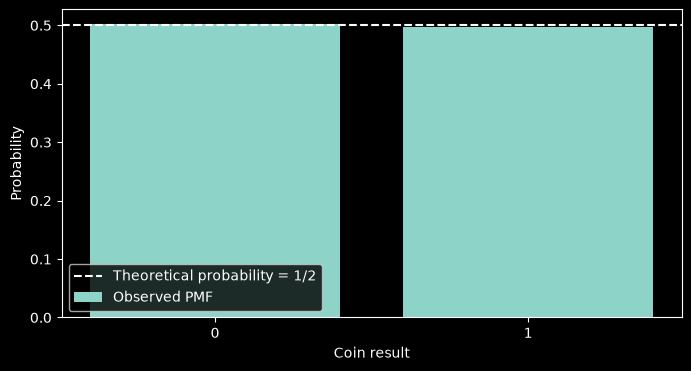

Sum of observed probabilities: 1.0


In [154]:
tosses = rng.integers(0, 2, size=3000)
values = np.arange(0, 2)
pmf = np.array([(tosses == value).mean() for value in values])
plt.figure(figsize=(8, 4))
plt.bar(values, pmf, label='Observed PMF')
plt.axhline(1/2, linestyle='--', label='Theoretical probability = 1/2')
plt.xticks(values)
plt.xlabel('Coin result')
plt.ylabel('Probability')
plt.legend()
plt.show()
print('Sum of observed probabilities:', pmf.sum())

# Part 4: Continuous Probability and Gaussian Distribution

Using the AveRooms feature:

1. Calculate the Mean and Standard Deviation.
2. Fit a Gaussian Distribution to the data.
3. Plot the actual data histogram and the fitted Gaussian PDF.
4. Calculate the Gaussian probability that AveRooms is between 4 and 6.
5. Calculate the observed fraction of values in the same interval and compare both results.

In [155]:
rooms = df['AveRooms'].to_numpy()
mean = rooms.mean()
std_dev = rooms.std()

print(f"AveRooms: Mean = {mean:.2f}, Standard Deviation = {std_dev:.2f}")

AveRooms: Mean = 5.43, Standard Deviation = 2.47


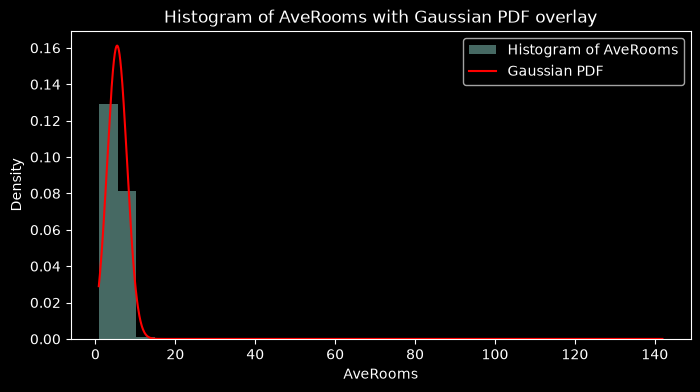

In [156]:
gaussian_pdf = stats.norm.pdf(rooms, loc=mean, scale=std_dev)
plt.figure(figsize=(8, 4))
plt.hist(rooms, bins=30, density=True, alpha=0.5, label='Histogram of AveRooms')
plt.plot(np.sort(rooms), gaussian_pdf[np.argsort(rooms)], color='red', label='Gaussian PDF')
plt.title('Histogram of AveRooms with Gaussian PDF overlay')
plt.xlabel('AveRooms')
plt.ylabel('Density')
plt.legend()
plt.show()


In [157]:
probability_between_4_and_6 = stats.norm.cdf(6, loc=mean, scale=std_dev) - stats.norm.cdf(4, loc=mean, scale=std_dev)
print(f"Probability that AveRooms is between 4 and 6: {probability_between_4_and_6:.4f}")

observed_fraction = ((rooms >= 4) & (rooms <= 6)).mean()
print(f"Observed fraction of AveRooms between 4 and 6: {observed_fraction:.4f}")

if np.isclose(probability_between_4_and_6, observed_fraction, atol=0.01):
    print("The Gaussian probability and the observed fraction are approximately equal.")
else:
    print("The Gaussian probability and the observed fraction are not approximately equal.")


Probability that AveRooms is between 4 and 6: 0.3095
Observed fraction of AveRooms between 4 and 6: 0.5991
The Gaussian probability and the observed fraction are not approximately equal.


# Part 5: Joint, Conditional Probability and Bayes' Theorem

Using HouseAge and MedHouseVal:

1. Divide HouseAge into three groups using quantiles:
   - New
   - Middle-aged
   - Old
2. Divide MedHouseVal into three groups:
   - Low
   - Medium
   - High
3. Create a Frequency Table using pd.crosstab().
4. Calculate the Joint Probability Table.
5. Calculate the Marginal Probability of each HouseAge group.
6. Calculate:
P(High Value| Old House)

7. Verify the result using Bayes' Theorem.

In [158]:
df["HouseAgeGroup"] = pd.qcut(df["HouseAge"], q=3, labels=["New", "Middle-aged", "Old"])
df["MedHouseValGroup"] = pd.qcut(df["MedHouseVal"], q=3, labels=["Low", "Medium", "High"])

counts = pd.crosstab(df["MedHouseValGroup"], df["HouseAgeGroup"])
print("Contingency Table (Counts):") 
display(counts)

Contingency Table (Counts):


HouseAgeGroup,New,Middle-aged,Old
MedHouseValGroup,,,
Low,2609,2264,2011
Medium,2395,2525,1956
High,2134,2369,2377


In [159]:
N = counts.to_numpy().sum()

joint = counts / N
print("Joint Probability Distribution:")
display(joint.round(3))

Joint Probability Distribution:


HouseAgeGroup,New,Middle-aged,Old
MedHouseValGroup,,,
Low,0.126,0.110,0.097
Medium,0.116,0.122,0.095
High,0.103,0.115,0.115


In [160]:
p_house_age = counts.sum(axis=0) / N
print("Marginal Probability Distribution for HouseAgeGroup:")
display(p_house_age.round(3))

Marginal Probability Distribution for HouseAgeGroup:


HouseAgeGroup
New            0.346
Middle-aged    0.347
Old            0.307
dtype: float64

In [161]:
p_value_given_house_age = counts.div(counts.sum(axis=0), axis=1)
print('P(High Value | Old House) =', round(p_value_given_house_age.loc['High', 'Old'], 3))

P(High Value | Old House) = 0.375


In [171]:
p_old_given_high = counts.loc['High', 'Old'] / counts.loc['High'].sum()
p_high = counts.loc['High'].sum() / N
p_old  = counts['Old'].sum() / N
bayes_result = p_old_given_high * p_high / p_old
print('Bayes theorem:', round(bayes_result, 3))

Bayes theorem: 0.375


# Part 6: MAP Bayesian Classifier

Build a Bayesian Classifier using AveRooms to predict whether a housing block has a high or low house value.

1. Create a Binary Target:
   - Class 1: MedHouseVal is greater than its median.
   - Class 0: Otherwise.
2. Split the dataset into 75% Training and 25% Testing.
3. Calculate the Prior Probability for each class.
4. Calculate the Mean and Standard Deviation of AveRooms for each class using training data only.
5. Implement the MAP Classifier using Gaussian Log-Likelihood.
6. Calculate the Testing Accuracy and Confusion Matrix.
7. Plot the Likelihood × Prior curves for both classes.

In [163]:
median_house_value = df['MedHouseVal'].median()
y = (df['MedHouseVal'] > median_house_value).astype(int)

In [164]:
x = df["AveRooms"].to_numpy()
x_train, x_test , y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)
x_train

array([5.28823529, 6.36432161, 6.11006289, ..., 3.98671727, 6.39534884,
       3.40257649], shape=(15480,))

In [165]:
priors = np.array([(y == k).mean() for k in (0, 1)])
print("Prior probabilities:")
print(f"P(MedHouseVal > median) = {priors[1]:.4f}")
print(f"P(MedHouseVal <= median) = {priors[0]:.4f}")

Prior probabilities:
P(MedHouseVal > median) = 0.4999
P(MedHouseVal <= median) = 0.5001


In [166]:
x_mean_train = np.array([x_train[y_train == k].mean() for k in (0, 1)])
x_std_train = np.array([x_train[y_train == k].std() for k in (0, 1)])

print("Mean and Standard Deviation of AveRooms for each class in the training set:")
for k in (0, 1):
    print(f"Class {k}: Mean = {x_mean_train[k]:.4f}, Std Dev = {x_std_train[k]:.4f}")

Mean and Standard Deviation of AveRooms for each class in the training set:
Class 0: Mean = 5.2013, Std Dev = 2.3249
Class 1: Mean = 5.6703, Std Dev = 2.4927


In [167]:
log_scores = np.column_stack([norm.logpdf(x_test, x_mean_train[k], x_std_train[k]) + np.log(priors[k]) for k in (0, 1)])
print(log_scores[:5])

[[-2.5496809  -2.7015651 ]
 [-2.45790726 -2.55778363]
 [-2.59410654 -2.75644331]
 [-2.54114108 -2.54532837]
 [-2.4633498  -2.52827897]]


In [168]:
y_pred = np.argmax(log_scores, axis=1)
y_pred

array([0, 0, 0, ..., 0, 1, 0], shape=(5160,))

In [169]:
print('Priors:', priors, 'Means:', x_mean_train, 'Standard deviations:', x_std_train)
print('Test accuracy:', round(accuracy_score(y_test, y_pred), 3))

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))

Priors: [0.50014535 0.49985465] Means: [5.20133282 5.67034874] Standard deviations: [2.32492106 2.49271208]
Test accuracy: 0.593
Confusion Matrix:
[[2281  294]
 [1807  778]]


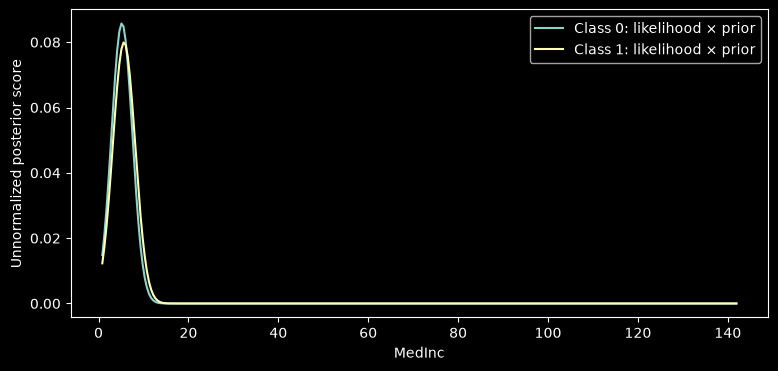

In [170]:
xx = np.linspace(x.min(), x.max(), 300)
plt.figure(figsize=(9,4))
for k in (0,1):
    plt.plot(xx, norm.pdf(xx, x_mean_train[k], x_std_train[k])*priors[k], label=f'Class {k}: likelihood × prior')
plt.xlabel('MedInc'); plt.ylabel('Unnormalized posterior score'); plt.legend(); plt.show()